<a href="https://colab.research.google.com/github/Wapikkk/text-summarize-nlp/blob/evaluation/notebooks/04_evalutaion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **04 - Evaluasi dan Analisis**
Tujuan: membandingkan semua model (extractive dan abstractive) pada data test yang sama dengan satu skrip evaluasi.

**Input**: file prediksi JSONL di results/ dengan format sesuai yang ada di Drive bersama {"id", "reference", "prediction"}, serta test.jsonl (untuk panjang dokumen dan analisis error).

**Output**: tabel ROUGE-1/2/L (precision, recall, F1) beserta convidence interval, BERTScore, analisis panjang dan waktu, analisis error otomatis, contoh kualitatif, dan sampel anotasi manual. Semua disimpan di folder evaluation/ di Drive.


## **Install Package & Import Package**
Memasang `rouge-score` (ROUGE) dan `bert-score` (BERTScore), mengimpor library, dan menghubungkan Google Drive. Kalau tidak di Colab, path Drive tidak dipasang dan notebook memakai path lokal.

In [3]:
!pip install -q rouge-score bert-score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import os, re, json, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from rouge_score import rouge_scorer

from google.colab import drive

from bert_score import score as bert_score
from matplotlib.patches import Patch

try:
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"

try:
    drive.mount("/content/drive")
except ImportError:
    print("Bukan di Colab, memakai path lokal.")

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
SEED = 42
random.seed(SEED); np.random.seed(SEED)
print("Device:", DEVICE)

Mounted at /content/drive
Device: cuda


## **Konfigurasi**
Lokasi file dan opsi evaluasi. `USE_BERTSCORE = False` melewati BERTScore yang mengunduh model dan memakai runtime GPU. `BOOTSTRAP_N` adalah jumlah resampling untuk selang kepercayaan 95%. `N_ANNOTATE` adalah jumlah contoh yang disiapkan untuk anotasi error manual.

In [5]:
DRIVE_DIR  = "/content/drive/MyDrive/dokumen_nlp"
RESULT_DIR = f"{DRIVE_DIR}/results"       # JSONL prediksi semua model (kontrak tim)
TEST_PATH  = f"{DRIVE_DIR}/test.jsonl"    # dokumen asli test (untuk panjang dokumen dan analisis error)
EVAL_DIR   = f"{DRIVE_DIR}/evaluation"    # keluaran evaluasi (CSV dan gambar)
os.makedirs(EVAL_DIR, exist_ok=True)

USE_BERTSCORE = True
BOOTSTRAP_N   = 1000
N_ANNOTATE    = 30
METRICS = {"rouge1": "R1", "rouge2": "R2", "rougeL": "RL"}

## **Load Hasil Prediksi**
Membaca semua `extractive_*.jsonl` dan `abstractive_*.jsonl`, serta catatan waktu (`*_run_info.json`). Hanya `id` yang ada di semua model yang dipakai, dan kolom `reference` hanya dilakukan pengecekan saja, sehingga semua model dinilai pada contoh yang persis sama. Tiap model diberi label yang mudah dibaca (mis. `TextRank (k=3)`).

In [6]:
def read_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

def read_json(path):
    return json.load(open(path, encoding="utf-8")) if os.path.exists(path) else {}

ext_info = read_json(f"{RESULT_DIR}/extractive_run_info.json")
abs_info = read_json(f"{RESULT_DIR}/abstractive_run_info.json")

BASE_NAME = {"tfidf": "TF-IDF", "textrank": "TextRank", "lsa": "LSA", "lead": "Lead-k"}
def label(stem):
    if stem == "abstractive_lstm":
        return "GRU+attention"
    if stem == "abstractive_mt5_small":
        return "mT5-small"
    m = re.match(r"extractive_(\w+?)(_k2)?$", stem)
    if not m:
        return stem
    base, k2 = m.groups()
    k = ext_info.get(base + ("_k2" if k2 else ""), {}).get("k", "?")
    return f"{BASE_NAME.get(base, base)} (k={k}" + (", setara panjang)" if k2 else ")")

files = [p for p in sorted(glob.glob(f"{RESULT_DIR}/*.jsonl"))
         if os.path.basename(p).startswith(("extractive_", "abstractive_"))]
raw = {os.path.basename(p)[:-6]: read_jsonl(p) for p in files}
assert raw, f"Tidak ada file prediksi di {RESULT_DIR}"

# hanya id yang ada di semua model, urutan mengikuti model pertama
first = next(iter(raw))
common = set.intersection(*[{r["id"] for r in rows} for rows in raw.values()])
ids = [r["id"] for r in raw[first] if r["id"] in common]
by_id = {stem: {r["id"]: r for r in rows} for stem, rows in raw.items()}
refs = [by_id[first][i]["reference"] for i in ids]

for stem in raw:
    n_diff = sum(by_id[stem][i]["reference"] != by_id[first][i]["reference"] for i in ids)
    if n_diff:
        print(f"PERINGATAN: {stem} punya {n_diff} reference yang berbeda dari {first}")

test = {r["id"]: r for r in read_jsonl(TEST_PATH)}
docs = [test[i]["document"] if i in test else "" for i in ids]
print("Contoh dengan dokumen:", sum(1 for d in docs if d), "dari", len(ids))

preds_by_model, stem_of, family = {}, {}, {}
for stem in raw:
    name = label(stem)
    preds_by_model[name] = [by_id[stem][i]["prediction"] for i in ids]
    stem_of[name] = stem
    family[name] = "abstractive" if stem.startswith("abstractive_") else "extractive"

print("Model:", list(preds_by_model))
print("Jumlah contoh dievaluasi:", len(ids))

Contoh dengan dokumen: 4778 dari 4778
Model: ['GRU+attention', 'mT5-small', 'Lead-k (k=4)', 'Lead-k (k=2, setara panjang)', 'LSA (k=4)', 'LSA (k=2, setara panjang)', 'TextRank (k=3)', 'TextRank (k=2, setara panjang)', 'TF-IDF (k=4)', 'TF-IDF (k=2, setara panjang)']
Jumlah contoh dievaluasi: 4778


## **Menghitung ROUGE**
ROUGE-1, ROUGE-2, dan ROUGE-L dihitung per contoh dengan `rouge_score` (precision, recall, F1), lalu dirata-rata. Tabel diurutkan menurut ROUGE-1 F1. Karena ringkasan referensi WikiLingua berupa judul yang pendek.

In [7]:
scorer = rouge_scorer.RougeScorer(list(METRICS), use_stemmer=False)

scores = {}   # model -> {"R1": {"p","r","f"}, ...} (array per contoh)
for name, preds in preds_by_model.items():
    acc = {k: {"p": [], "r": [], "f": []} for k in METRICS.values()}
    for p, r in zip(preds, refs):
        s = scorer.score(r, p)
        for m, short in METRICS.items():
            acc[short]["p"].append(s[m].precision)
            acc[short]["r"].append(s[m].recall)
            acc[short]["f"].append(s[m].fmeasure)
    scores[name] = {k: {x: np.array(v) for x, v in d.items()} for k, d in acc.items()}

rows = []
for name in preds_by_model:
    row = {"model": name, "jenis": family[name]}
    for short in METRICS.values():
        for x, tag in (("p", "P"), ("r", "R"), ("f", "F")):
            row[f"{short}-{tag}"] = scores[name][short][x].mean()
    rows.append(row)
summary = pd.DataFrame(rows).set_index("model").sort_values("R1-F", ascending=False)
summary.round(4)

,jenis,R1-P,R1-R,R1-F,R2-P,R2-R,R2-F,RL-P,RL-R,RL-F
model,,,,,,,,,,
mT5-small,abstractive,0.3574,0.2382,0.2639,0.1273,0.0833,0.0923,0.2827,0.1906,0.2095
TextRank (k=3),extractive,0.1955,0.3365,0.2258,0.0538,0.0961,0.0625,0.1397,0.2497,0.1631
"TextRank (k=2, setara panjang)",extractive,0.2285,0.2699,0.2239,0.0622,0.0742,0.0607,0.1671,0.2025,0.1651
LSA (k=4),extractive,0.1724,0.3426,0.2094,0.0454,0.0953,0.0557,0.1229,0.2543,0.1510
Lead-k (k=4),extractive,0.1627,0.3269,0.1989,0.0396,0.0854,0.0490,0.1124,0.2365,0.1392
TF-IDF (k=4),extractive,0.1601,0.3371,0.1980,0.0398,0.0890,0.0496,0.1136,0.2491,0.1420
"Lead-k (k=2, setara panjang)",extractive,0.2075,0.2214,0.1934,0.0488,0.0549,0.0459,0.1517,0.1665,0.1427
"LSA (k=2, setara panjang)",extractive,0.2050,0.2092,0.1848,0.0499,0.0524,0.0451,0.1549,0.1608,0.1403
"TF-IDF (k=2, setara panjang)",extractive,0.1898,0.2119,0.1778,0.0427,0.0506,0.0405,0.1427,0.1622,0.1343


## **Convidence Interval dan Uji Perbedaan**
Convidence Interval 95% dihitung dengan **bootstrap** (resampling contoh test) untuk F1 tiap metrik. Lalu model extractive terbaik dibandingkan dengan model abstractive terbaik lewat **bootstrap berpasangan** pada selisih F1. Kalau interval selisih tidak memuat 0, perbedaannya konsisten.

Beberapa bagian berasal dari artikel yang sama, jadi interval ini sedikit lebih optimistis daripada kenyataan.

In [8]:
def boot_means(x, n=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)
    x = np.asarray(x)
    idx = rng.integers(0, len(x), size=(n, len(x)))
    return x[idx].mean(axis=1)

ci_rows = []
for name in summary.index:
    row = {"model": name}
    for short in METRICS.values():
        f = scores[name][short]["f"]
        lo, hi = np.percentile(boot_means(f), [2.5, 97.5])
        row[f"{short}-F1 [95% CI]"] = f"{f.mean():.4f} [{lo:.4f}, {hi:.4f}]"
    ci_rows.append(row)
ci_df = pd.DataFrame(ci_rows).set_index("model")
print(ci_df.to_string())

best_ext = summary[summary["jenis"] == "extractive"]["R1-F"].idxmax()
best_abs = summary[summary["jenis"] == "abstractive"]["R1-F"].idxmax()
print(f"\nExtractive terbaik : {best_ext}")
print(f"Abstractive terbaik: {best_abs}")
for short in METRICS.values():
    d = scores[best_abs][short]["f"] - scores[best_ext][short]["f"]
    lo, hi = np.percentile(boot_means(d), [2.5, 97.5])
    print(f"{short}-F1 selisih (abstractive - extractive): {d.mean():+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]")

                                         R1-F1 [95% CI]           R2-F1 [95% CI]           RL-F1 [95% CI]
model                                                                                                    
mT5-small                       0.2639 [0.2605, 0.2673]  0.0923 [0.0898, 0.0948]  0.2095 [0.2066, 0.2125]
TextRank (k=3)                  0.2258 [0.2228, 0.2285]  0.0625 [0.0609, 0.0642]  0.1631 [0.1612, 0.1652]
TextRank (k=2, setara panjang)  0.2239 [0.2208, 0.2268]  0.0607 [0.0590, 0.0626]  0.1651 [0.1628, 0.1673]
LSA (k=4)                       0.2094 [0.2068, 0.2120]  0.0557 [0.0543, 0.0574]  0.1510 [0.1491, 0.1529]
Lead-k (k=4)                    0.1989 [0.1966, 0.2012]  0.0490 [0.0478, 0.0504]  0.1392 [0.1377, 0.1408]
TF-IDF (k=4)                    0.1980 [0.1955, 0.2005]  0.0496 [0.0481, 0.0510]  0.1420 [0.1404, 0.1438]
Lead-k (k=2, setara panjang)    0.1934 [0.1910, 0.1960]  0.0459 [0.0445, 0.0474]  0.1427 [0.1410, 0.1446]
LSA (k=2, setara panjang)       0.1848 [0.1821

## **Grafik Perbandingan**
Tiga panel (ROUGE-1, ROUGE-2, ROUGE-L, semua F1) dengan urutan model yang sama (diurutkan menurut ROUGE-1 F1). Warna membedakan jenis model: biru untuk extractive, oranye untuk abstractive. Gambar disimpan ke `evaluation/rouge_f1.png`.

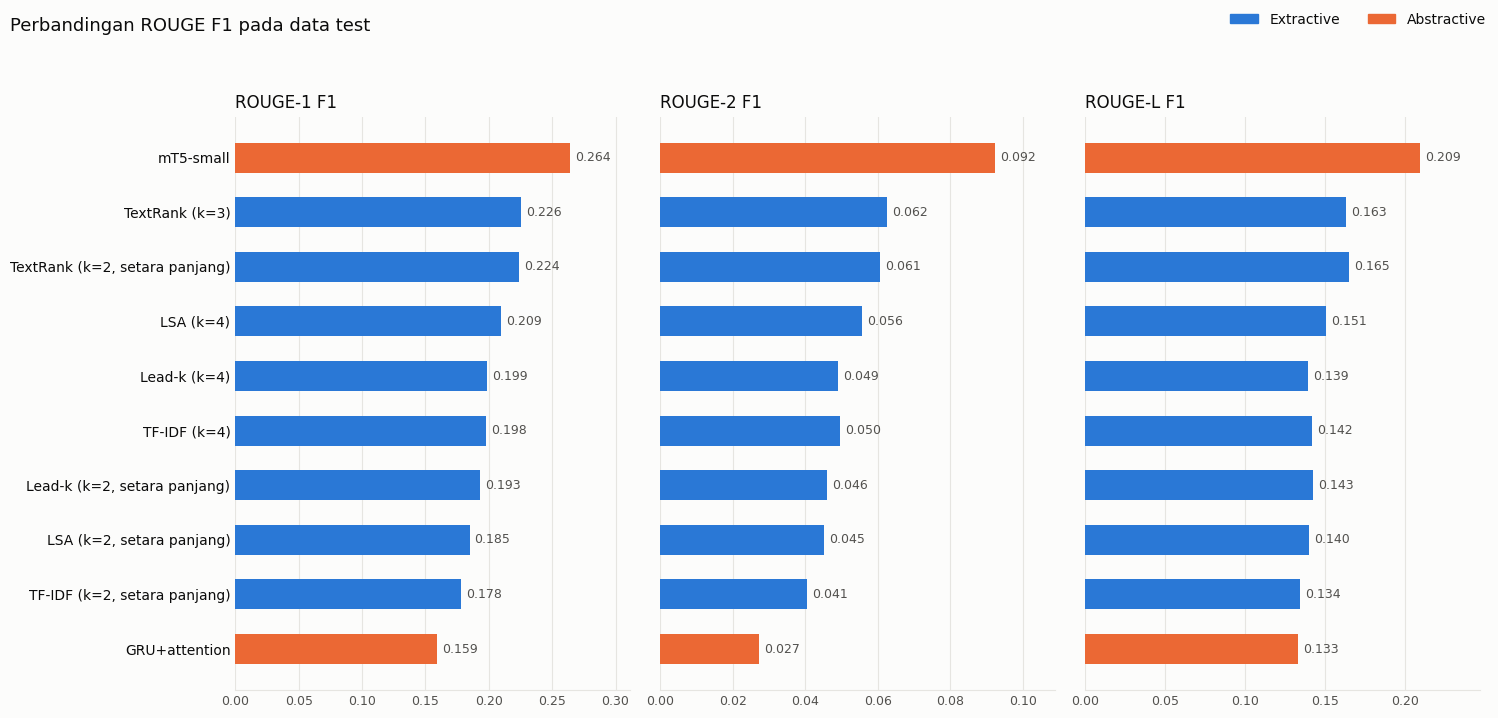

In [9]:
COL_EXT, COL_ABS = "#2a78d6", "#eb6834"          # slot 1 dan 2 palet kategorikal
INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e1"

order = list(summary.sort_values("R1-F").index)   # terbawah ke teratas (barh)
fig, axes = plt.subplots(1, 3, figsize=(15, 0.5 * len(order) + 2.2), sharey=True, facecolor=SURFACE)
for ax, (col, title) in zip(axes, [("R1-F", "ROUGE-1 F1"), ("R2-F", "ROUGE-2 F1"), ("RL-F", "ROUGE-L F1")]):
    vals = summary.loc[order, col].values
    colors = [COL_ABS if family[n] == "abstractive" else COL_EXT for n in order]
    ax.set_facecolor(SURFACE)
    ax.barh(range(len(order)), vals, height=0.55, color=colors)
    vmax = vals.max()
    for y, v in enumerate(vals):
        ax.text(v + vmax * 0.015, y, f"{v:.3f}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(0, vmax * 1.18)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=10, color=INK)
    ax.set_title(title, fontsize=12, color=INK, loc="left")
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", colors=INK2, labelsize=9, length=0)
    ax.tick_params(axis="y", length=0)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
fig.legend(handles=[Patch(color=COL_EXT, label="Extractive"), Patch(color=COL_ABS, label="Abstractive")],
           loc="upper right", frameon=False, ncol=2, fontsize=10, labelcolor=INK)
fig.suptitle("Perbandingan ROUGE F1 pada data test", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(f"{EVAL_DIR}/rouge_f1.png", dpi=200, facecolor=SURFACE)
plt.show()

## **Analisis Panjang Ringkasan dan Panjang Dokumen**
Dua hal yang diperiksa pada bagian ini.

**Pertama**, panjang ringkasan rata-rata tiap model dibanding referensi (ROUGE recall naik kalau ringkasan memanjang, jadi panjang perlu dibandingkan dengan adil).

**Kedua**, skor ROUGE-1 F1 dipisah menurut panjang dokumen (pendek, sedang, panjang, dibagi tiga kelompok sama besar) untuk melihat apakah dokumen panjang lebih sulit, terutama bagi model yang memotong input.

In [10]:
wc = lambda t: len(t.split())
ref_len = np.array([wc(r) for r in refs])
doc_len = np.array([wc(d) for d in docs])

len_rows = []
for name, preds in preds_by_model.items():
    pl = np.array([wc(p) for p in preds])
    len_rows.append({"model": name, "kata/ringkasan": pl.mean(),
                     "rasio thd referensi": pl.mean() / ref_len.mean(),
                     "% prediksi kosong": (pl == 0).mean() * 100})
len_df = pd.DataFrame(len_rows).set_index("model").loc[summary.index]
print(f"Panjang referensi rata-rata: {ref_len.mean():.1f} kata | panjang dokumen rata-rata: {doc_len.mean():.1f} kata\n")
print(len_df.round(2).to_string())

if doc_len.sum() > 0:
    bucket = pd.qcut(pd.Series(doc_len), 3, labels=["pendek", "sedang", "panjang"], duplicates="drop")
    print("\nBatas kelompok panjang dokumen (kata):", pd.Series(doc_len).quantile([1/3, 2/3]).round(0).tolist())
    bucket_df = pd.DataFrame({name: pd.Series(scores[name]["R1"]["f"]).groupby(bucket, observed=True).mean()
                              for name in summary.index}).T
    print("\nROUGE-1 F1 menurut panjang dokumen:")
    print(bucket_df.round(4).to_string())

Panjang referensi rata-rata: 30.6 kata | panjang dokumen rata-rata: 349.0 kata

                                kata/ringkasan  rasio thd referensi  % prediksi kosong
model                                                                                 
mT5-small                                17.85                 0.58                0.0
TextRank (k=3)                           51.26                 1.68                0.0
TextRank (k=2, setara panjang)           34.82                 1.14                0.0
LSA (k=4)                                58.23                 1.90                0.0
Lead-k (k=4)                             59.18                 1.93                0.0
TF-IDF (k=4)                             62.33                 2.04                0.0
Lead-k (k=2, setara panjang)             30.14                 0.99                0.0
LSA (k=2, setara panjang)                28.80                 0.94                0.0
TF-IDF (k=2, setara panjang)             32.11    

## **Waktu Training dan Inferensi**
Diambil dari `extractive_run_info.json` dan `abstractive_run_info.json`. Model extractive tidak dilatih, sehingga hanya punya waktu inferensi. Kolom yang kosong (`NaN`) berarti catatannya tidak tersimpan (mis. sesi training terputus sehingga `train_time_s` tidak tertulis).

In [11]:
ABS_KEY = {"abstractive_lstm": "lstm", "abstractive_mt5_small": "pretrained"}
time_rows = []
for name in summary.index:
    stem = stem_of[name]
    if stem.startswith("extractive_"):
        d = ext_info.get(stem[len("extractive_"):], {})
        train_t = None
    else:
        d = abs_info.get(ABS_KEY.get(stem, ""), {})
        train_t = d.get("train_time_s")
    infer_t, n = d.get("infer_time_s"), d.get("n_test") or abs_info.get("n_test") or len(ids)
    time_rows.append({"model": name, "training (detik)": train_t, "inferensi (detik)": infer_t,
                      "ms/contoh": (infer_t / n * 1000) if infer_t else None})
time_df = pd.DataFrame(time_rows).set_index("model")
time_df.round(2)

,training (detik),inferensi (detik),ms/contoh
model,,,
mT5-small,None,835.9,174.95
TextRank (k=3),None,27.5,5.76
"TextRank (k=2, setara panjang)",None,27.6,5.78
LSA (k=4),None,21.1,4.42
Lead-k (k=4),None,1.1,0.23
TF-IDF (k=4),None,5.4,1.13
"Lead-k (k=2, setara panjang)",None,1.1,0.23
"LSA (k=2, setara panjang)",None,23.2,4.86
"TF-IDF (k=2, setara panjang)",None,4.3,0.90


## **BERTScore**
Mengukur kemiripan makna dengan embedding BERT multi-language (`lang="id"` memakai `bert-base-multilingual-cased`). Hasil per model disimpan di `evaluation/bertscore.json` dan dipakai lagi pada run berikutnya, jadi hanya model baru yang dihitung ulang.

In [12]:
bs_path = f"{EVAL_DIR}/bertscore.json"
bs = read_json(bs_path)
if USE_BERTSCORE:
    for name, preds in preds_by_model.items():
        if name in bs:
            continue
        cands = [p if p.strip() else "-" for p in preds]
        P, R, F = bert_score(cands, refs, lang="id", batch_size=32, device=DEVICE, verbose=False)
        bs[name] = {"BS-P": float(P.mean()), "BS-R": float(R.mean()), "BS-F1": float(F.mean())}
        json.dump(bs, open(bs_path, "w"), indent=2)
        print(name, {k: round(v, 4) for k, v in bs[name].items()})
bs_df = pd.DataFrame(bs).T.reindex(summary.index) if bs else pd.DataFrame(index=summary.index)
bs_df.round(4)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

... (27 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


TF-IDF (k=2, setara panjang) {'BS-P': 0.6829, 'BS-R': 0.6945, 'BS-F1': 0.6875}


,BS-P,BS-R,BS-F1
model,,,
mT5-small,0.7590,0.7372,0.7471
TextRank (k=3),0.6893,0.7130,0.7000
"TextRank (k=2, setara panjang)",0.6987,0.7022,0.6995
LSA (k=4),0.6794,0.7143,0.6955
Lead-k (k=4),0.6771,0.7112,0.6929
TF-IDF (k=4),0.6719,0.7170,0.6928
"Lead-k (k=2, setara panjang)",0.6933,0.6942,0.6929
"LSA (k=2, setara panjang)",0.6917,0.6901,0.6898
"TF-IDF (k=2, setara panjang)",0.6829,0.6945,0.6875


## **Analisis Error Otomatis**
Indikator sederhana per model, berguna sebagai bahan analisis error di laporan:
- **perulangan trigram / kalimat**: ada tiga kata berurutan atau satu kalimat yang muncul berulang di ringkasan.
- **mengandung `<unk>`**: model dari nol menghasilkan token kosakata tidak dikenal (OOV).
- **novelty unigram / bigram**: porsi kata (atau pasangan kata) di ringkasan yang **tidak ada di dokumen**. Model extractive hampir 0 karena menyalin kalimat. Nilai tinggi pada abstractive menunjukkan penulisan ulang, tetapi juga bisa menandakan **hallucination**.
- **angka tidak ada di dokumen**: ringkasan memuat angka yang tidak muncul di dokumen (indikator kasar hallucination).

Semua ini hanya **indikator**, bukan bukti. Pemeriksaan manual pada sampel anotasi di bawah tetap diperlukan.

In [13]:
TOK = re.compile(r"\w+", re.UNICODE)
toks = lambda t: TOK.findall(t.lower())

doc_uni = [set(toks(d)) for d in docs]
doc_bi  = [set(zip(toks(d), toks(d)[1:])) for d in docs]
doc_num = [set(re.findall(r"\d+", d)) for d in docs]

def repeat_flags(p):
    t = toks(p)
    tri = list(zip(t, t[1:], t[2:]))
    sents = [s.strip().lower() for s in re.split(r"(?<=[.!?])\s+", p) if s.strip()]
    return len(tri) != len(set(tri)), len(sents) != len(set(sents))

err_rows = []
for name, preds in preds_by_model.items():
    rep_tri, rep_sent, unk, short, num_bad, nov_u, nov_b = [], [], [], [], [], [], []
    for i, p in enumerate(preds):
        rt, rs = repeat_flags(p)
        rep_tri.append(rt); rep_sent.append(rs)
        unk.append("<unk>" in p.lower())
        t = toks(p)
        short.append(len(t) < 5)
        nums = set(re.findall(r"\d+", p))
        num_bad.append(bool(nums - doc_num[i]))
        if t and docs[i]:
            nov_u.append(np.mean([w not in doc_uni[i] for w in t]))
            bi = list(zip(t, t[1:]))
            nov_b.append(np.mean([b not in doc_bi[i] for b in bi]) if bi else 0.0)
    err_rows.append({"model": name,
                     "% repetisi trigram": np.mean(rep_tri) * 100,
                     "% repetisi kalimat": np.mean(rep_sent) * 100,
                     "% mengandung <unk>": np.mean(unk) * 100,
                     "% terlalu pendek (<5 kata)": np.mean(short) * 100,
                     "% angka tidak ada di dokumen": np.mean(num_bad) * 100,
                     "novelty unigram (%)": (np.mean(nov_u) * 100) if nov_u else np.nan,
                     "novelty bigram (%)": (np.mean(nov_b) * 100) if nov_b else np.nan})
err_df = pd.DataFrame(err_rows).set_index("model").loc[summary.index]
err_df.round(2)

,% repetisi trigram,% repetisi kalimat,% mengandung <unk>,% terlalu pendek (<5 kata),% angka tidak ada di dokumen,novelty unigram (%),novelty bigram (%)
model,,,,,,,
mT5-small,0.57,0.08,0.0,0.46,3.56,12.66,37.52
TextRank (k=3),48.18,0.80,0.0,0.00,0.00,0.00,2.84
"TextRank (k=2, setara panjang)",30.58,0.42,0.0,0.00,0.00,0.00,2.39
LSA (k=4),63.29,1.72,0.0,0.00,0.00,0.00,3.39
Lead-k (k=4),33.99,0.08,0.0,0.00,0.00,0.00,0.02
TF-IDF (k=4),37.00,0.23,0.0,0.00,0.00,0.00,3.43
"Lead-k (k=2, setara panjang)",10.44,0.06,0.0,0.00,0.00,0.00,0.01
"LSA (k=2, setara panjang)",32.80,1.42,0.0,0.00,0.00,0.00,2.90
"TF-IDF (k=2, setara panjang)",19.88,0.13,0.0,0.00,0.00,0.00,2.94


## **Contoh Kualitatif**
Menampilkan beberapa contoh untuk analisis di laporan: tiga contoh **terbaik** dan tiga **terburuk** menurut ROUGE-1 F1 model abstractive terbaik, plus lima contoh acak. Setiap contoh memperlihatkan dokumen (potongan awal), referensi, dan prediksi model abstractive serta extractive terbaik. Gunakan contoh ini untuk kutipan "benar" dan "salah" di bagian analisis.

In [14]:
show_models = [n for n in summary.index if family[n] == "abstractive"] + [best_ext]
focus = scores[best_abs]["R1"]["f"]
rank = np.argsort(focus)
rng = np.random.default_rng(SEED)
groups = [("TERBAIK", list(rank[::-1][:3])), ("TERBURUK", list(rank[:3])),
          ("ACAK", list(rng.choice(len(ids), size=5, replace=False)))]

def show(i):
    print("-" * 100)
    print(f"id={ids[i]} | panjang dokumen={doc_len[i]} kata")
    print("DOKUMEN  :", docs[i][:350].replace("\n", " "), "...")
    print("REFERENSI:", refs[i])
    for n in show_models:
        print(f"{n:<28}(R1-F={scores[n]['R1']['f'][i]:.3f}): {preds_by_model[n][i]}")

for title, idxs in groups:
    print("=" * 100); print(title); print("=" * 100)
    for i in idxs:
        show(int(i))

TERBAIK
----------------------------------------------------------------------------------------------------
id=10841_0 | panjang dokumen=28 kata
DOKUMEN  : Untuk membuat kotak tiga lampu yang menggunakan lebih banyak cahaya yang didifusikan, Anda harus memotong sisi bagian atas kotak. Jangan lupa sisakan margin pinggir agar kotaknya tetap kokoh. ...
REFERENSI: Potong bagian atas kotak.
mT5-small                   (R1-F=1.000): Potong bagian atas kotak.
GRU+attention               (R1-F=0.353): siapkan kotak yang. letakkan kotak di atas kotak. di bagian atas. atas kertas.
TextRank (k=3)              (R1-F=0.188): Untuk membuat kotak tiga lampu yang menggunakan lebih banyak cahaya yang didifusikan, Anda harus memotong sisi bagian atas kotak. Jangan lupa sisakan margin pinggir agar kotaknya tetap kokoh.
----------------------------------------------------------------------------------------------------
id=4785_0 | panjang dokumen=38 kata
DOKUMEN  : Adonan tepung bir ini memberikan hasil 

## **Sampel untuk Anotasi Error Manual**
Menyimpan sampel acak ke `evaluation/error_annotation_sample.csv` (buka di Excel/Sheets). Kolom kosong di sisi kanan diisi manual oleh tim dengan 0/1 atau catatan singkat: **halusinasi** (informasi yang tidak ada di dokumen), **repetisi**, **informasi_hilang** (poin penting terlewat), **oov_unk** (kata tidak dikenal), dan **catatan**. Ringkasan jumlahnya dipakai sebagai tabel analisis error di laporan.

In [15]:
sample_idx = sorted(np.random.default_rng(SEED).choice(len(ids), size=min(N_ANNOTATE, len(ids)), replace=False))
ann = pd.DataFrame({"id": [ids[i] for i in sample_idx],
                    "dokumen (awal)": [docs[i][:400] for i in sample_idx],
                    "referensi": [refs[i] for i in sample_idx]})
for n in show_models:
    ann[f"prediksi {n}"] = [preds_by_model[n][i] for i in sample_idx]
for c in ["halusinasi", "repetisi", "informasi_hilang", "oov_unk", "catatan"]:
    ann[c] = ""
ann.to_csv(f"{EVAL_DIR}/error_annotation_sample.csv", index=False, encoding="utf-8-sig")
print("Disimpan:", f"{EVAL_DIR}/error_annotation_sample.csv", "| jumlah contoh:", len(ann))

Disimpan: /content/drive/MyDrive/dokumen_nlp/evaluation/error_annotation_sample.csv | jumlah contoh: 30


## **Menyimpan Tabel untuk Laporan**
Menggabungkan angka utama (ROUGE F1, BERTScore F1, panjang, waktu inferensi) dalam satu tabel, lalu menyimpan semua tabel ke `evaluation/` dalam bentuk CSV. File-file kecil ini boleh diunggah ke GitHub (folder `report/`), sedangkan `bertscore.json` dan gambar opsional.

In [16]:
main = summary[["jenis", "R1-F", "R2-F", "RL-F"]].copy()
if "BS-F1" in bs_df.columns:
    main["BERTScore-F1"] = bs_df["BS-F1"]
main["kata/ringkasan"] = len_df["kata/ringkasan"]
main["inferensi (detik)"] = time_df["inferensi (detik)"]
main = main.rename(columns={"R1-F": "ROUGE-1 F1", "R2-F": "ROUGE-2 F1", "RL-F": "ROUGE-L F1"})

outputs = {"rouge_summary.csv": summary, "rouge_ci.csv": ci_df, "panjang_ringkasan.csv": len_df,
           "waktu.csv": time_df, "bertscore.csv": bs_df, "analisis_error_otomatis.csv": err_df,
           "tabel_utama.csv": main}
if doc_len.sum() > 0:
    outputs["rouge1_per_panjang_dokumen.csv"] = bucket_df
for fname, df in outputs.items():
    df.to_csv(f"{EVAL_DIR}/{fname}", encoding="utf-8-sig")
print("Tersimpan di", EVAL_DIR)
for fname in outputs:
    print(" -", fname)
main.round(4)

Tersimpan di /content/drive/MyDrive/dokumen_nlp/evaluation
 - rouge_summary.csv
 - rouge_ci.csv
 - panjang_ringkasan.csv
 - waktu.csv
 - bertscore.csv
 - analisis_error_otomatis.csv
 - tabel_utama.csv
 - rouge1_per_panjang_dokumen.csv


,jenis,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1,BERTScore-F1,kata/ringkasan,inferensi (detik)
model,,,,,,,
mT5-small,abstractive,0.2639,0.0923,0.2095,0.7471,17.8524,835.9
TextRank (k=3),extractive,0.2258,0.0625,0.1631,0.7000,51.2604,27.5
"TextRank (k=2, setara panjang)",extractive,0.2239,0.0607,0.1651,0.6995,34.8202,27.6
LSA (k=4),extractive,0.2094,0.0557,0.1510,0.6955,58.2311,21.1
Lead-k (k=4),extractive,0.1989,0.0490,0.1392,0.6929,59.1766,1.1
TF-IDF (k=4),extractive,0.1980,0.0496,0.1420,0.6928,62.3296,5.4
"Lead-k (k=2, setara panjang)",extractive,0.1934,0.0459,0.1427,0.6929,30.1409,1.1
"LSA (k=2, setara panjang)",extractive,0.1848,0.0451,0.1403,0.6898,28.8020,23.2
"TF-IDF (k=2, setara panjang)",extractive,0.1778,0.0405,0.1343,0.6875,32.1147,4.3


## **Catatan untuk Laporan**
- **Metrik resmi** adalah ROUGE-1/2/L F1 dari sel di atas. Tuliskan juga precision dan recall (ada di `rouge_summary.csv`), BERTScore, selang kepercayaan, serta waktu.
- **Perbandingan yang adil:** bandingkan versi extractive `k=2` (panjang mirip referensi) dengan model abstractive, selain versi `k` terbaik.
- **Keterbatasan** yang perlu disebut: dokumen dipotong (GRU 300 kata, mT5 512 token); referensi berupa judul langkah sehingga ROUGE-2 rendah; GRU dilatih dari nol sehingga rentan OOV dan repetisi; catatan epoch dan waktu training mungkin tidak lengkap (lihat tabel waktu).
- **Analisis error:** pakai tabel otomatis sebagai petunjuk, lalu isi `error_annotation_sample.csv` secara manual untuk angka yang bisa dipertanggungjawabkan.
- **Setelah selesai:** unggah file CSV di `evaluation/` ke folder `report/` di branch `evaluation` GitHub, dan simpan notebook ini sebagai `notebooks/04_evaluation.ipynb`.